### Packages

In [66]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [67]:
import matplotlib.pyplot as plt
import sklearn.datasets as datasets
import pandas as pd
import numpy as np
from scipy.stats import norm,beta,chi2
import seaborn as sns
sns.set_style("whitegrid")

### Functions

In [68]:
from pit import pit
from pit import plot_pit_histograms,test_and_interpret_pit
from ldf import ldf
from utils.utils import tlp,geom_3f2
from beta_transform import online_beta_calibration, plot_parameter_evolution
from Log_likelihood import tlp_pdf, log_score_comparison

### DGP

In [69]:
### Fix the seed for reproducibility
np.random.seed(0)

### Define DGP constants
phi = 0.9
sigma_x = 0.3 # 1# 
sigma_y = 0.3 # 0.5 # 
sigma_z = 0.1 # 1# 
K = 20  # number of forecasters
T = 2001  ## number of time steps

# Comment this section for other simulations
##############################################
levels = np.asarray([0]*50 + [-1]*50 + [1]*50 + [-1]*50 + [0]*200 + [-1]*400 + [0]*50 + [-1]*50 + [1]*50 + [-1]*10 + [1]*10 + [0]*10 + [-1]*10 + [1]*10  + [0]*50 + [1]*50 + [0]*50 + [-1]*50 + [1]*400 + [0]*50 + [-1]*50 + [1]*50 + [0]*50 + [0]*201)

def generate_dgp(levels):
    v_t = norm.rvs(size=T)
    e_t = norm.rvs(size=T)
    x = np.asarray([sigma_x * v_t[0]])
    for i in range(T-1):
        x = np.append(x, phi * x[-1] + sigma_x * v_t[i+1])
    y = phi * x + e_t * sigma_y
    y = y + levels[:T]
    return x, y


def get_forecasts(levels):
    x, y = generate_dgp(levels)
    z = x + norm.rvs(size=(K,T)) * sigma_z
    p = z # phi * z
    p = (p.T + np.linspace(-2,2,K)).T
    forecasts = pd.DataFrame(p)
    return forecasts, y

forecasts, sim_y = get_forecasts(levels)
##############################################

### Time Constant Simulation

In [70]:
#def generate_levels():
#    transitions = np.asarray([-1, 0, 1])
#    transition_matrix = np.array([[0.99, 0.005, 0.005],[0.005, 0.99, 0.005],[0.005, 0.005, 0.99]]) # np.array([[0.98, 0.01, 0.01],[0.01, 0.98, 0.01],[0.01, 0.01, 0.98]])
#    levels = [0]
#    for i in range(1,T):  
#        level_index = np.where(transitions == levels[-1])[0][0]
#        levels.append(np.random.choice(transitions, replace=True, p=transition_matrix[level_index]))
#    return np.asarray(levels)

#def generate_dgp(levels):
#    v_t = norm.rvs(size=T)
#    e_t = norm.rvs(size=T)
#    x = np.asarray([sigma_x * v_t[0]])
#    for i in range(T-1):
#        x = np.append(x, phi * x[-1] + sigma_x * v_t[i+1])
#    y = phi * x + e_t * sigma_y
#    y = y + levels[:T]
#    return x, y


#def get_forecasts(levels):
#    x, y = generate_dgp(levels)
#    z = x + norm.rvs(size=(K,T)) * sigma_z
#    p = z # phi * z
#    p = (p.T + np.linspace(-2,2,K)).T
#    forecasts = pd.DataFrame(p)
#    return forecasts, y

#levels = generate_levels()

#forecasts, sim_y = get_forecasts(levels)

### Time-varying Simulation

In [71]:
#def generate_levels2():
#    transitions = np.asarray([-1, 0, 1])
#    transition_matrix = np.array([[0.99, 0.005, 0.005],[0.005, 0.99, 0.005],[0.005, 0.005, 0.99]])
#    transition_matrix2 = np.array([[0.98, 0.01, 0.01],[0.01, 0.98, 0.01],[0.01, 0.01, 0.98]])
#    levels = [0]
#    for i in range(1,T):  
#        level_index = np.where(transitions == levels[-1])[0][0]
#        if i<1000:
#            levels.append(np.random.choice(transitions, replace=True, p=transition_matrix[level_index]))
#        else:
#            levels.append(np.random.choice(transitions, replace=True, p=transition_matrix2[level_index]))
#    return np.asarray(levels)


#def generate_dgp(levels):
#    v_t = norm.rvs(size=T)
#    e_t = norm.rvs(size=T)
#    x = np.asarray([sigma_x * v_t[0]])
#    for i in range(T-1):
#        x = np.append(x, phi * x[-1] + sigma_x * v_t[i+1])
#    y = phi * x + e_t * sigma_y
#    y = y + levels[:T]
#    return x, y


#def get_forecasts(levels):
#    x, y = generate_dgp(levels)
#    z = x + norm.rvs(size=(K,T)) * sigma_z
#    p = z # phi * z
#    p = (p.T + np.linspace(-2,2,K)).T
#    forecasts = pd.DataFrame(p)
#    return forecasts, y

#levels = generate_levels2()

#forecasts, sim_y = get_forecasts(levels)

In [72]:
forecasts_lik = pd.DataFrame(norm.pdf(sim_y, loc=forecasts.to_numpy(), scale=sigma_y))

# forecasters's cdfs
forecasts_cdf    = pd.DataFrame(norm.cdf(sim_y, loc=forecasts.to_numpy(), scale=sigma_y))  

# log likelihoods
log_likelihoods = np.log(forecasts_lik).astype(float).to_numpy() 

### LDF hyperparameters

In [73]:
discount_factors = np.array([1, 0.99, 0.95, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.001])
c = 10**-20 

### 2-level LDF(softmax, softmax)

In [74]:
%%time
res_ldf_2 = ldf(log_likelihoods, levels=2, discount_factors=[discount_factors, discount_factors], activation_functions=["softmax", "softmax"], c=c)
res_ldf_2_df = pd.DataFrame({'discount factors': discount_factors, 'log likelihood': res_ldf_2["logscores"].mean(axis=1)})
res_ldf_2_df

CPU times: total: 1.5 s
Wall time: 1.62 s


,discount factors,log likelihood
0,1.000,-0.471795
1,0.990,-0.437265
2,0.950,-0.405797
3,0.900,-0.398013
4,0.800,-0.395621
5,0.700,-0.397694
6,0.600,-0.400453
7,0.500,-0.403269
8,0.400,-0.406206
9,0.300,-0.409135


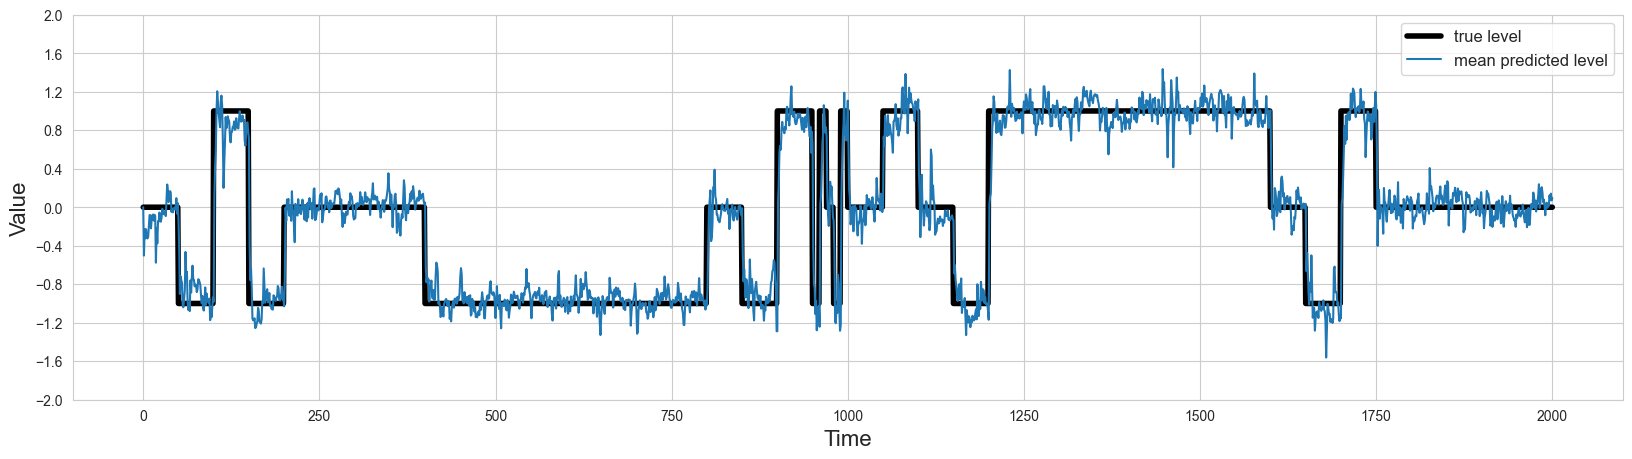

In [75]:
mean_pred_level = (np.linspace(-2,2,20) * res_ldf_2["weights"][5]).sum(axis=1)
sns.color_palette("tab10")
fig, ax = plt.subplots(1, 1, figsize=(20,5))
lns1 = ax.plot(range(len(levels)), levels, lw=4, label="true level", color="black")
lns2 = ax.plot(range(len(levels)), mean_pred_level , label="mean predicted level", color="tab:blue")
#lns3 = ax.plot(range(20, len(levels)), y[20:] , lw=0.5,label="y", color="red")
lns = lns1+lns2#+lns3
labs = [l.get_label() for l in lns]
ax.set_ylim(-2, 2)
ax.set_yticks(np.arange(-2, 2.4, 0.4))
ax.set_xlabel("Time", fontsize=16)
ax.set_ylabel("Value", fontsize=16)
ax.legend(lns, labs, loc='upper right', fontsize=12)

### x-grid

In [76]:
f = forecasts.values
mu_min, mu_max = f.min(), f.max()  # observed forecast means
margin = 3*sigma_y
x_min = mu_min - margin
x_max = mu_max + margin
M     = 1001  # odd so there’s a grid‐point exactly at the median
x_grid = np.linspace(x_min, x_max, M)

### Beta Transform

In [77]:
tlp_param = {
    'forecast': forecasts,
    'x': x_grid,
    'weights': res_ldf_2['weights'],
    'sigma_y': sigma_y
    }

beta_transformed_pit = online_beta_calibration(
    x=x_grid,
    y_observations=sim_y,
    pool_func=tlp,
    pool_param=tlp_param,
    geom_3f2=geom_3f2,
    # Core BFGS/Newton parameters
    a0=1.0,
    b0=1.0,
    gamma=0.05,
    eta0=1.2,
    tau=50,
    alpha=0.55,

    # Basic calibration parameters
    outer_loop_freq=70,              # Correction frequency (t_freq in algorithm)
    min_samples=40,                  # Minimum samples for corrections (n_min in algorithm)
    
    # Algorithm 2: Shape detection parameters
    significance_level=0.15,          # α - significance level for chi-square tests
    k_bins_for_detection=10,          # k - number of bins for shape detection 
    
    # Algorithm 3: Shape-specific correction parameters
    correction_strength=0.4,        # λ - blend parameter for corrections
    param_floor=0.25,               # Lower bound for α,β parameters
    param_ceiling=5.00,             # Upper bound for α,β parameters
    
    # Window management
    rolling_window_size=75,        # w - rolling window size for corrections
    x_constant=1.2,
    # Numerical stability
    eps=1e-5)

Starting Online Beta Calibration
  Models (P): 12
  Time steps (T): 2001
  Grid points (M): 1001
  Initial parameters: α₀=1.0, β₀=1.0
  Learning rate: η₀=1.2, τ=50, α=0.55
  Correction strength: 0.4
------------------------------------------------------------
Step    0: α=0.9929, β=1.0056
Step  200: α=1.1322, β=1.0779
Step  400: α=1.6835, β=1.7371
Step  600: α=1.5780, β=1.6517
Step  800: α=1.2797, β=1.3428
Step 1000: α=1.2583, β=1.3174
Step 1200: α=1.2601, β=1.3188
Step 1400: α=1.1621, β=1.2041
Step 1600: α=1.1697, β=1.2060
Step 1800: α=1.1377, β=1.1737
Step 2000: α=1.1767, β=1.2118
------------------------------------------------------------
Online Beta Calibration Complete


### Beta Parameters Evolution

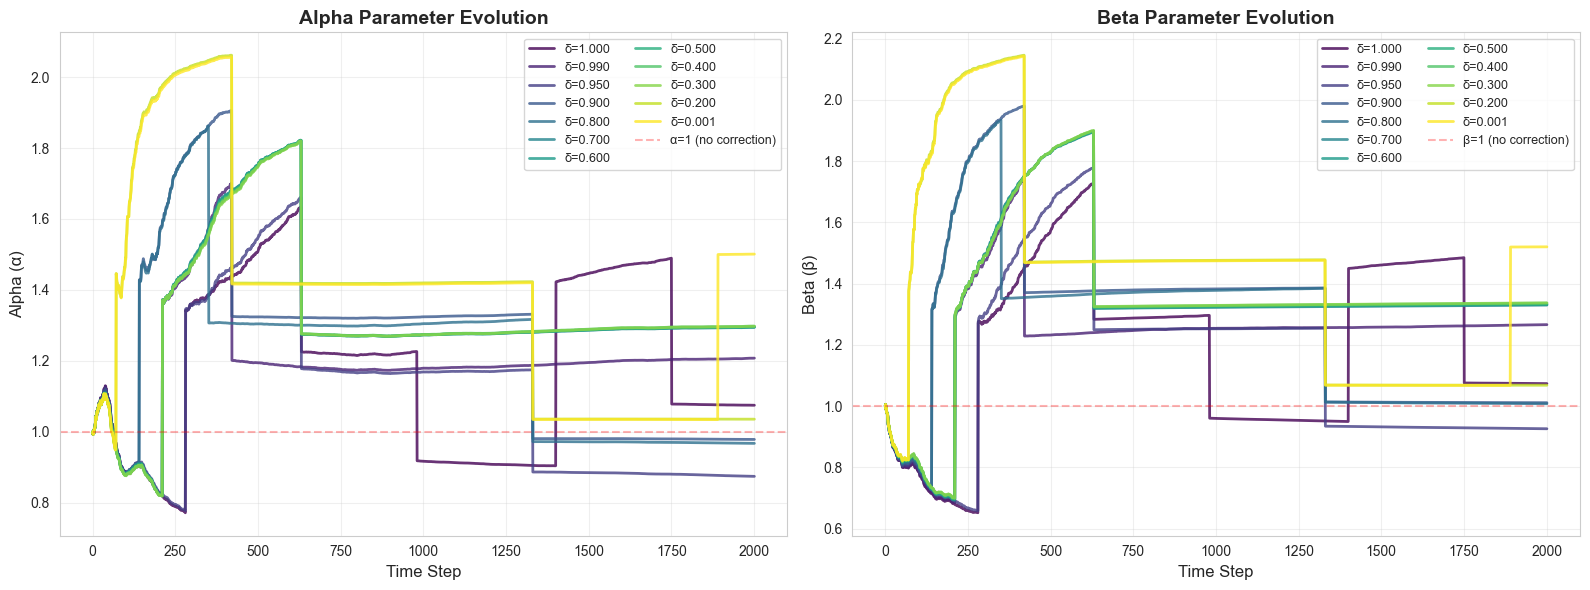

In [78]:
plot_parameter_evolution(beta_transformed_pit, discount_factors)

### Uniformity Comparison Results

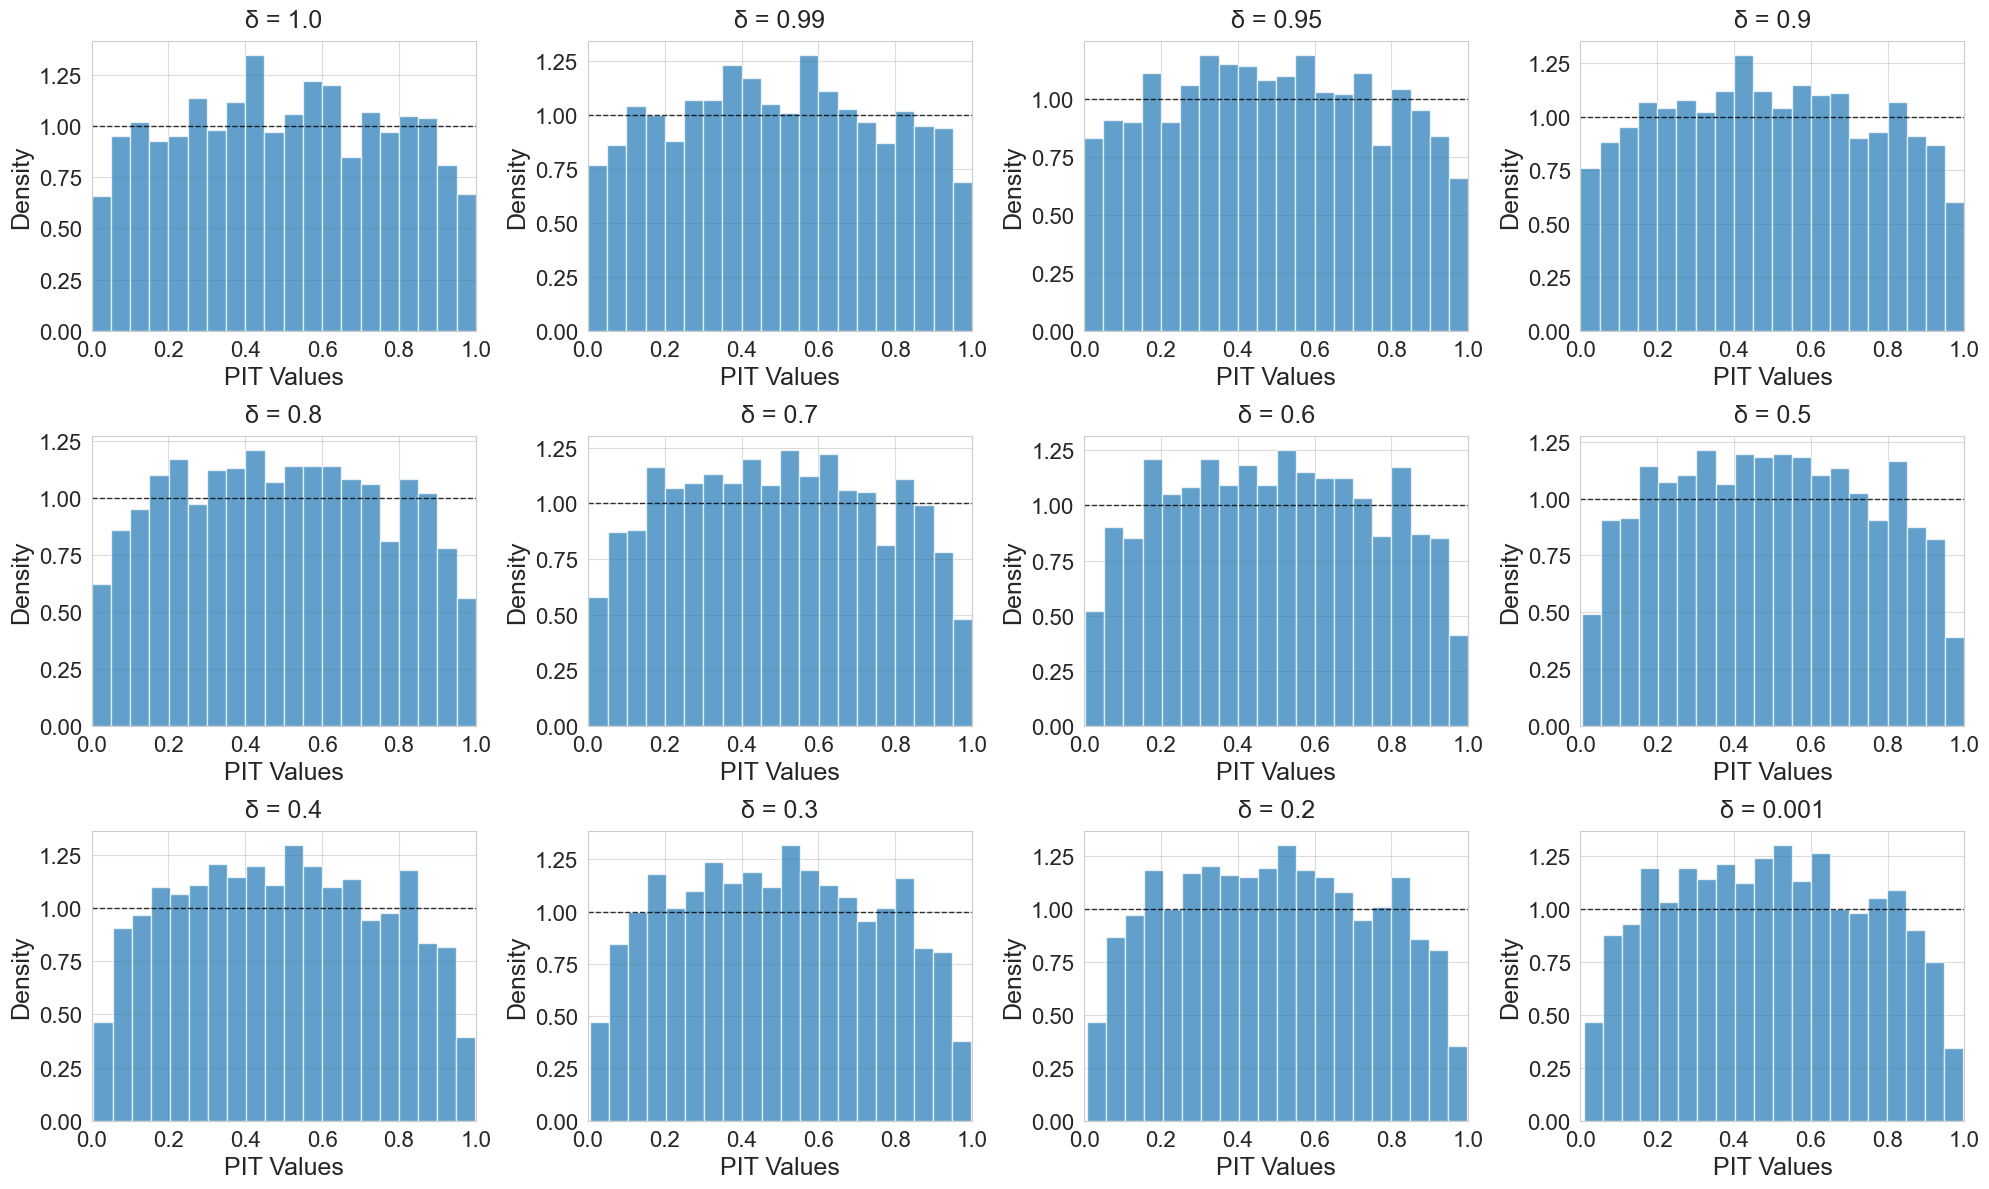

In [79]:
linear_pool = tlp(forecasts,x_grid, res_ldf_2['weights'],sigma_y)

Raw_pit = pit(linear_pool, x_grid, sim_y)

plot_pit_histograms(Raw_pit, model_names = discount_factors)

In [80]:
_, beta_orig_df = test_and_interpret_pit(
    pit_values=Raw_pit,
    discount_factors=discount_factors
)
beta_orig_df

,Model,Tests_Passed,KS_Test,Chi2_Test,JB_Test,AD_Test,Mean_Test,Variance_Test,KL_Test,Coverage_5%_Test,Coverage_95%_Test
0,δ = 1.0,1/9,FAIL,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL
1,δ = 0.99,1/9,FAIL,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL
2,δ = 0.95,2/9,FAIL,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,PASS,FAIL
3,δ = 0.9,1/9,FAIL,FAIL,FAIL,FAIL,PASS,FAIL,FAIL,FAIL,FAIL
4,δ = 0.8,2/9,FAIL,FAIL,FAIL,PASS,PASS,FAIL,FAIL,FAIL,FAIL
5,δ = 0.7,2/9,FAIL,FAIL,FAIL,PASS,PASS,FAIL,FAIL,FAIL,FAIL
6,δ = 0.6,3/9,FAIL,FAIL,PASS,PASS,PASS,FAIL,FAIL,FAIL,FAIL
7,δ = 0.5,3/9,FAIL,FAIL,PASS,PASS,PASS,FAIL,FAIL,FAIL,FAIL
8,δ = 0.4,3/9,FAIL,FAIL,PASS,PASS,PASS,FAIL,FAIL,FAIL,FAIL
9,δ = 0.3,3/9,FAIL,FAIL,PASS,PASS,PASS,FAIL,FAIL,FAIL,FAIL


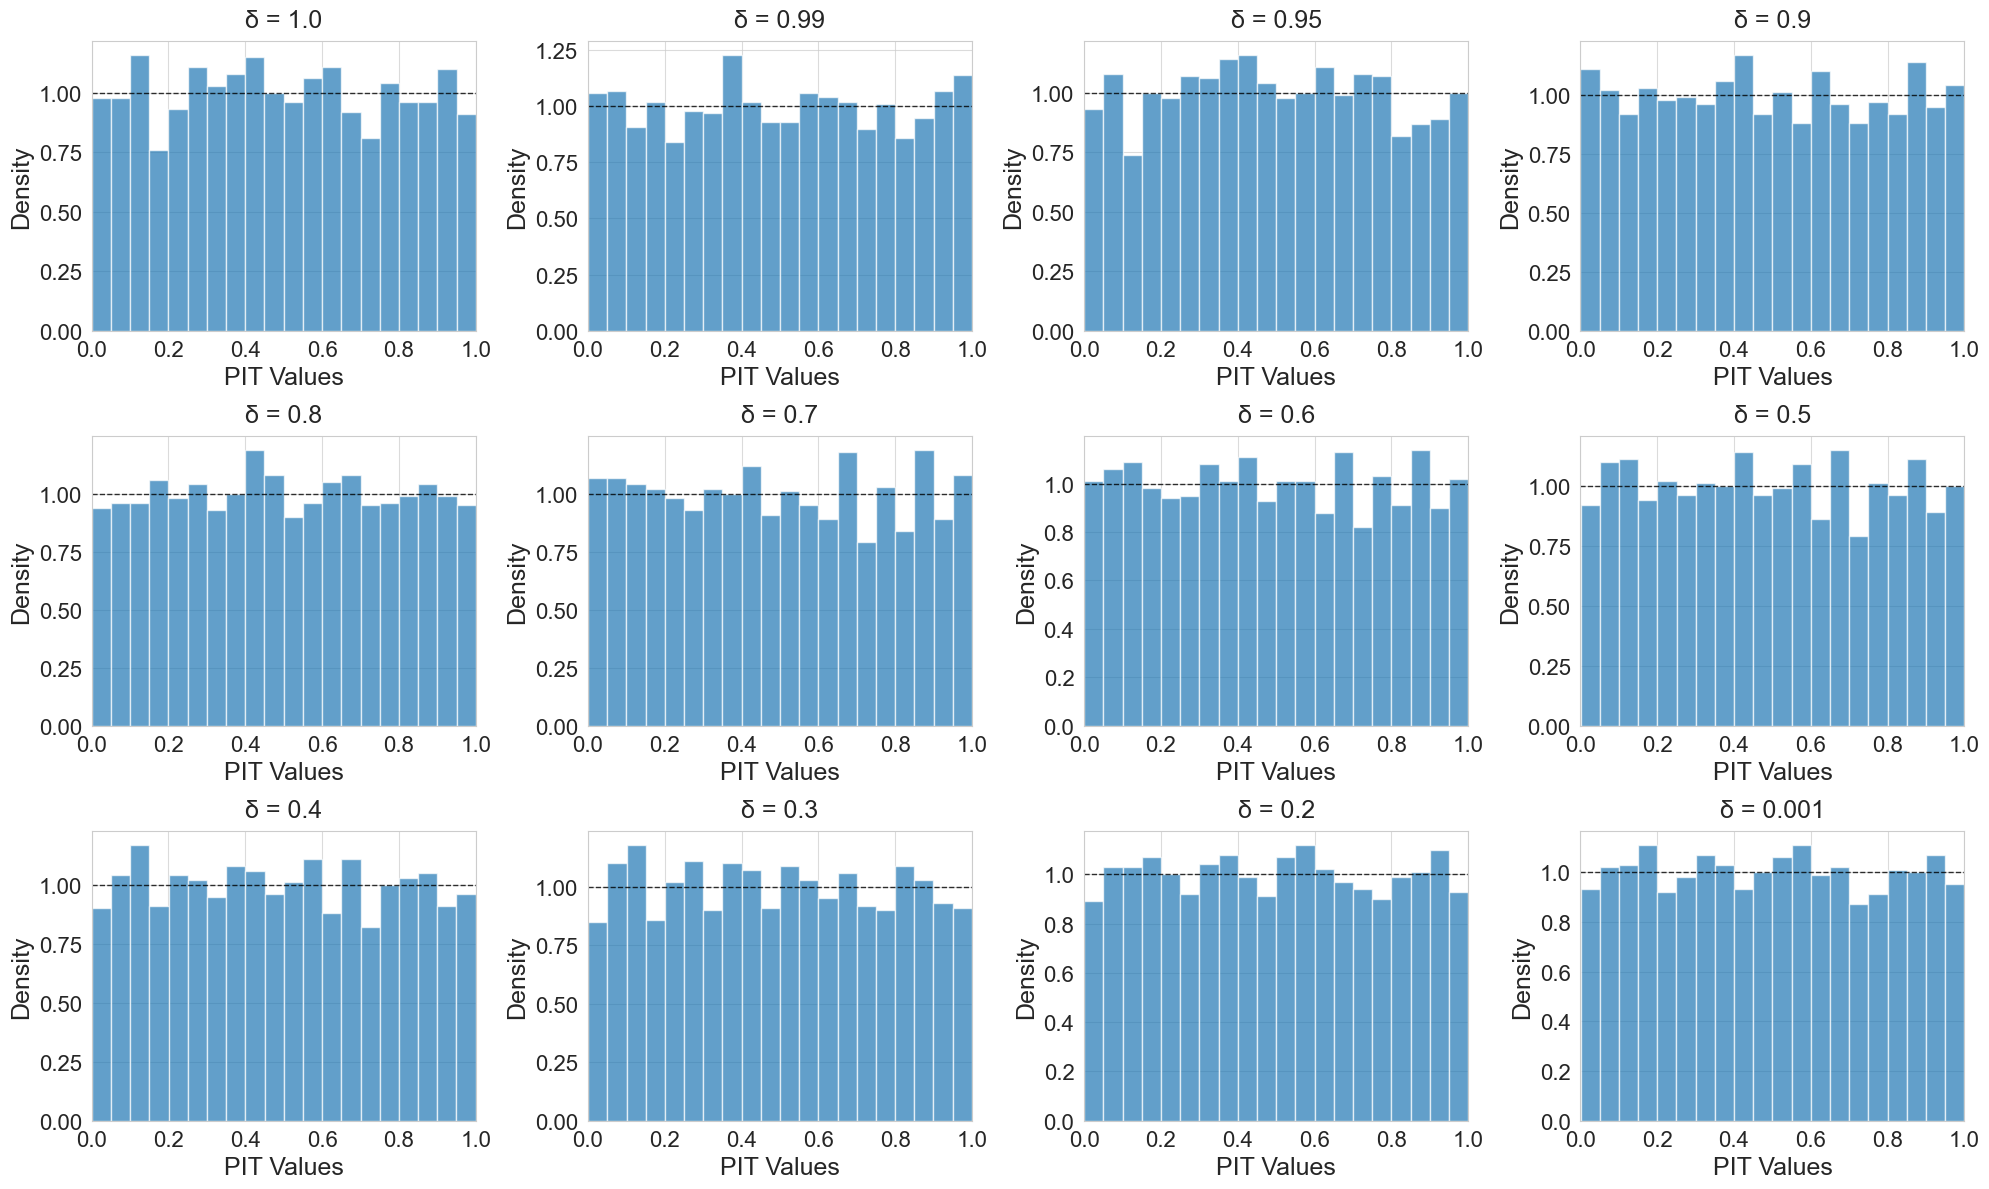

In [81]:
plot_pit_histograms(beta_transformed_pit['all_calibrated_cdfs'], model_names = discount_factors)

In [82]:
_, beta_tran_df = test_and_interpret_pit(
    pit_values=beta_transformed_pit['all_calibrated_cdfs'],
    discount_factors=discount_factors
)
beta_tran_df

,Model,Tests_Passed,KS_Test,Chi2_Test,JB_Test,AD_Test,Mean_Test,Variance_Test,KL_Test,Coverage_5%_Test,Coverage_95%_Test
0,δ = 1.0,7/9,PASS,PASS,FAIL,FAIL,PASS,PASS,PASS,PASS,PASS
1,δ = 0.99,7/9,PASS,PASS,FAIL,FAIL,PASS,PASS,PASS,PASS,PASS
2,δ = 0.95,6/9,PASS,PASS,FAIL,FAIL,PASS,FAIL,PASS,PASS,PASS
3,δ = 0.9,7/9,PASS,PASS,FAIL,FAIL,PASS,PASS,PASS,PASS,PASS
4,δ = 0.8,8/9,PASS,PASS,FAIL,PASS,PASS,PASS,PASS,PASS,PASS
5,δ = 0.7,9/9,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS
6,δ = 0.6,9/9,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS
7,δ = 0.5,9/9,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS
8,δ = 0.4,9/9,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS
9,δ = 0.3,9/9,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS,PASS


### Log-Likelihood Comparison

In [83]:
TLP_pdf = tlp_pdf(forecasts,x_grid, res_ldf_2['weights'],sim_y, sigma_y)
log_TLP_pdf = np.log(TLP_pdf)

In [84]:
beta_ll_result = log_score_comparison(beta_transformed_pit['all_calibrated_cdfs'], 
                           np.array(beta_transformed_pit['a_hist'][:,1:]), 
                           np.array(beta_transformed_pit['b_hist'][:,1:]), 
                           Raw_pit, 
                           TLP_pdf, 
                           log_TLP_pdf,
                           discount_factors)

beta_ll_result

,discount_factor,Before Calibration,After Calibration,Comparison
0,1.000,-0.471797,-0.484792,Lower Log Score
1,0.990,-0.437269,-0.447013,Lower Log Score
2,0.950,-0.405803,-0.419646,Lower Log Score
3,0.900,-0.398021,-0.408619,Lower Log Score
4,0.800,-0.395632,-0.393714,Higher Log Score
5,0.700,-0.397706,-0.387528,Higher Log Score
6,0.600,-0.400465,-0.384834,Higher Log Score
7,0.500,-0.403283,-0.383429,Higher Log Score
8,0.400,-0.406219,-0.383014,Higher Log Score
9,0.300,-0.409148,-0.383255,Higher Log Score


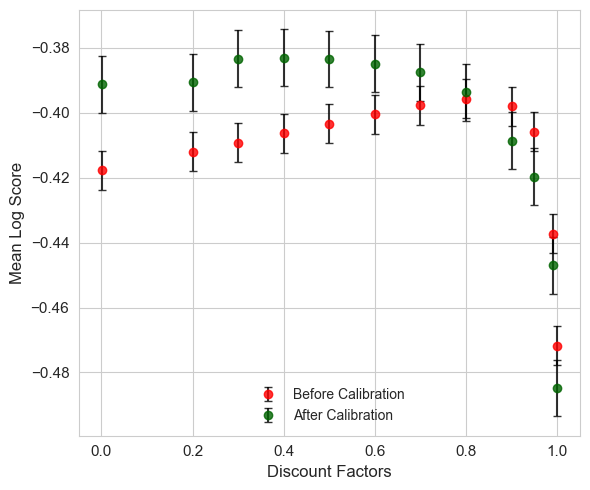

In [85]:
fig, ax = plt.subplots(1, 1, figsize=(6,5))

before_mean_log_score = beta_ll_result['Before Calibration']
after_mean_log_score = beta_ll_result['After Calibration']

# Example: assuming you have std errors (replace with your arrays)
before_std = np.std(before_mean_log_score) / np.sqrt(len(before_mean_log_score))
after_std = np.std(after_mean_log_score) / np.sqrt(len(after_mean_log_score))

ax.errorbar(discount_factors, before_mean_log_score, 
            yerr=before_std, fmt='o', 
            mfc='red', mec='red', ecolor='black', 
            label="Before Calibration", markersize=6, capsize=3, alpha=0.8)

ax.errorbar(discount_factors, after_mean_log_score, 
            yerr=after_std, fmt='o', 
            mfc='darkgreen', mec='darkgreen', ecolor='black', 
            label="After Calibration", markersize=6, capsize=3, alpha=0.8)
ax.set_ylabel("Mean Log Score", fontsize=12)
ax.set_xlabel("Discount Factors", fontsize=12)

ax.legend(loc="lower center", frameon=False, fontsize=10)
ax.tick_params(axis='both', labelsize=11)

fig.tight_layout()